# 03 · Customer segmentation: loss-making high-volume customers

**Roadmap step 3.** Business question:

> *Who are our high-volume customers that generate net losses, and how do they differ
> from profitable high-volume customers in recency, frequency, discounts, products and
> regions?*

**Context from step 2:** 155 of 793 customers are unprofitable (query 07), and discounts
above 20% drive most losses (queries 03-05).

**Definitions** (agreed before looking at results):

| Term | Definition | Why |
|---|---|---|
| High-volume | top 25% of customers by **gross sales** (before discount) | Net sales shrink with discounts, so ranking by net sales would push heavily discounted customers out of the group |
| Net loss | total profit 2014-2017 < 0 | |
| HV-loss / HV-profit | high-volume customers with / without a net loss | the two groups compared |
| Recency reference date | last order date in the data + 1 day (2017-12-31) | today's date would make every customer look inactive |

`gross_sales` assumes `sales` is recorded after discount; the assumption is tested in
notebook 01. All tables are built by `python -m src.build_database`
(`customer_features`, `customer_mix`, `customer_rfm`, `customer_clusters`), and the
comparisons come from `src/customer_comparison.py`.

**Leakage warning:** every customer feature here summarizes the full 2014-2017 history,
so none of it may be used as a feature in the step 4 order-line model.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import src.customer_comparison as cc
from src.build_database import DB_PATH, build_database
from src.segmentation import (CLUSTER_FEATURES, CONTRAST_FEATURES, N_CLUSTERS,
                              N_CLUSTERS_CONTRAST, cluster_matrix, evaluate_k)

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The DuckDB file is not in git; build it if it is missing.
if not DB_PATH.exists():
    build_database()

con = duckdb.connect(str(DB_PATH), read_only=True)
customers = cc.load_customers(con)


def show(df, pct=(), money=(), decimals=2):
    # Display a table with percentage and money columns formatted.
    fmt = {c: "{:.1%}" for c in pct}
    fmt.update({c: "${:,.0f}" for c in money})
    display(df.style.format(fmt, precision=decimals, thousands=","))

In [2]:
# Shared chart style (light mode, reference palette from the dataviz guide).
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
LOSS = "#e34948"                                     # HV-loss / loss pole (blue <-> red)
GROUP_COLORS = {"HV-loss": LOSS, "HV-profit": BLUE}
BAND_COLORS = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # ordinal blue ramp, 0% -> >40%

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TEXT_2, "ytick.color": TEXT_2, "font.size": 10, "text.color": TEXT,
})


def add_titles(fig, title, subtitle, top=0.86):
    # Left-aligned figure title and subtitle above the plot area.
    fig.text(0.015, 0.965, title, fontsize=12, fontweight="bold", color=TEXT, va="top")
    fig.text(0.015, 0.895, subtitle, fontsize=9, color=TEXT_2, va="top")
    fig.tight_layout(rect=(0, 0, 1, top))


def save(fig, name):
    fig.savefig(FIG_DIR / f"03_{name}.png", dpi=150)
    plt.show()

## 1. The groups

43 customers are high-volume and loss-making, 156 high-volume and profitable.

In [3]:
overview = cc.group_overview(customers)
show(overview, pct=["profit_margin", "share_of_total_profit"],
     money=["gross_sales", "sales", "profit"])

,customers,gross_sales,sales,profit,profit_margin,share_of_total_profit
volume_group,,,,,,
HV-loss,43,"$413,126","$228,771","$-52,784",-23.1%,-18.4%
HV-profit,156,"$1,185,196","$1,016,764","$200,347",19.7%,70.0%
Other,594,"$1,265,211","$1,051,384","$138,846",13.2%,48.5%


The 43 HV-loss customers bought \$413,126 at list price but paid \$228,771, and lost
\$52,784 in total (−23.1% margin), erasing 18.4% of company profit. The 156 HV-profit
customers earned \$200,347 (+19.7%), 70% of company profit.

## 2. Segmentations

**RFM:** 1-5 scores from average-rank percentiles (tied values always share a score;
recency inverted) and a six-segment R × F grid. Monetary is used for profiling only.

**K-Means:** behavior features only, with profit left out, so profitability can *test*
the clusters instead of defining them: log1p(recency, frequency, gross sales) and the
share of gross sales at >20% discount, standardized. A **contrast run without the
discount feature** tests whether discount behavior is what sets loss-makers apart.

k was chosen on four checks, looking only at the clustering features (not at profit or
the volume groups): inertia elbow, silhouette, smallest cluster ≥ 5% of customers, and
stability (mean Adjusted Rand Index ≥ 0.8 across 20 seeds and 50 bootstraps). This cell
reruns the sweep (about 40 seconds).

In [4]:
sweeps = {}
for name, columns in [("main", CLUSTER_FEATURES), ("contrast", CONTRAST_FEATURES)]:
    sweeps[name] = evaluate_k(cluster_matrix(customers, columns))
    print(f"{name}: {columns}")
    show(sweeps[name], decimals=3)

main: ['recency_days', 'frequency', 'gross_sales', 'high_discount_gross_share']


,k,inertia,silhouette,smallest_cluster_share,seed_ari,bootstrap_ari,passes_size,passes_stability
0,2,"2,269.257",0.269,0.376,0.992,0.902,True,True
1,3,"1,820.581",0.271,0.197,0.998,0.881,True,True
2,4,"1,541.649",0.231,0.161,0.987,0.813,True,True
3,5,"1,372.543",0.218,0.100,0.937,0.607,True,False
4,6,"1,250.569",0.222,0.078,0.549,0.566,True,False
5,7,"1,140.639",0.213,0.066,0.835,0.621,True,False
6,8,"1,075.607",0.207,0.066,0.705,0.541,True,False


contrast: ['recency_days', 'frequency', 'gross_sales']


,k,inertia,silhouette,smallest_cluster_share,seed_ari,bootstrap_ari,passes_size,passes_stability
0,2,"1,484.231",0.344,0.375,0.999,0.937,True,True
1,3,"1,191.013",0.251,0.236,1.000,0.663,True,False
2,4,984.382,0.259,0.108,0.992,0.685,True,False
3,5,853.649,0.251,0.077,0.989,0.663,True,False
4,6,771.644,0.229,0.044,0.563,0.461,False,False
5,7,703.661,0.236,0.033,0.589,0.453,False,False
6,8,643.689,0.243,0.026,0.564,0.517,False,False


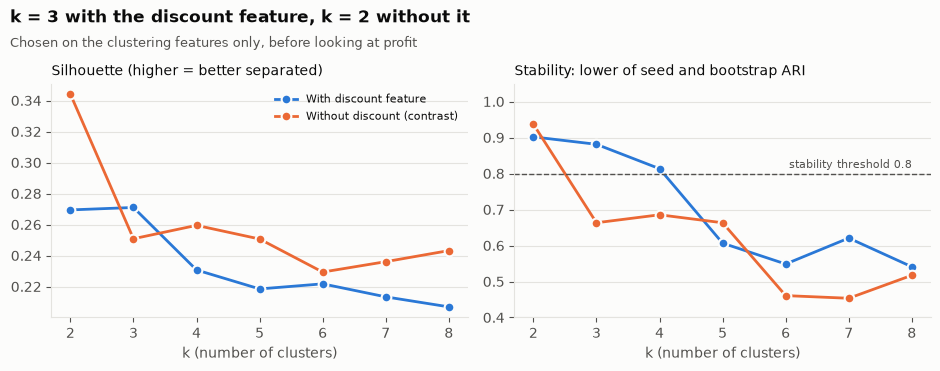

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
for name, color, label in [("main", BLUE, "With discount feature"),
                           ("contrast", ORANGE, "Without discount (contrast)")]:
    s = sweeps[name]
    ax1.plot(s["k"], s["silhouette"], color=color, lw=2, marker="o", ms=7,
             markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
    ax2.plot(s["k"], np.minimum(s["seed_ari"], s["bootstrap_ari"]), color=color, lw=2,
             marker="o", ms=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
ax2.axhline(0.8, color=TEXT_2, lw=1, ls="--")
ax2.annotate("stability threshold 0.8", (8, 0.8), xytext=(0, 4), textcoords="offset points",
             ha="right", fontsize=8, color=TEXT_2)
for ax, chosen in [(ax1, None), (ax2, None)]:
    ax.set_xlabel("k (number of clusters)")
    ax.grid(axis="x", visible=False)
ax1.set_title("Silhouette (higher = better separated)", loc="left", fontsize=10, color=TEXT)
ax2.set_title("Stability: lower of seed and bootstrap ARI", loc="left", fontsize=10, color=TEXT)
ax2.set_ylim(0.4, 1.05)
ax1.legend(frameon=False, fontsize=8, loc="upper right")
add_titles(fig, "k = 3 with the discount feature, k = 2 without it",
           "Chosen on the clustering features only, before looking at profit")
save(fig, "01_k_selection")

**Choice:** with the discount feature, k = 2, 3 and 4 pass the size and stability checks;
k = 3 has the best silhouette and is the inertia elbow. k = 2 was rejected because it
reproduces the no-discount contrast (ARI 0.925), i.e. it ignores the discount feature.
Without the discount feature only k = 2 passes. Cluster profiles (clustering features
only):

In [6]:
profile = (customers.groupby("cluster")[CLUSTER_FEATURES].median()
           .assign(customers=customers["cluster"].value_counts()))
show(profile[["customers"] + CLUSTER_FEATURES], decimals=2)

,customers,recency_days,frequency,gross_sales,high_discount_gross_share
cluster,,,,,
"Active, heavy-discount",156,70.50,6.00,"3,667.05",0.59
"Active, regular",400,47.00,7.00,"3,592.09",0.05
"Quiet, low volume",237,206.00,4.00,"1,012.85",0.01


## 3. How HV-loss customers differ from HV-profit customers

### 3.1 Per-customer metrics
Medians, with a bootstrap 95% interval for the difference (HV-loss − HV-profit) and a
Mann-Whitney p-value.

In [7]:
metrics = cc.compare_customer_metrics(customers)
show(metrics, decimals=3)

,metric,HV-loss median,HV-profit median,difference,ci_low,ci_high,mann_whitney_p
0,Recency (days since last order),72.000,49.000,23.000,-3.000,42.012,0.254
1,Frequency (orders),7.000,8.000,-1.000,-2.000,0.000,0.006
2,Tenure (days since first order),"1,253.000","1,242.500",10.500,-59.013,74.512,0.920
3,Gross sales ($),"7,754.450","6,616.065","1,138.385",105.113,"2,097.390",0.075
4,Average discount,0.241,0.133,0.109,0.068,0.127,0.000
5,Share of gross sales at >20% discount,0.751,0.097,0.654,0.523,0.725,0.000
6,Worst single line profit ($),-950.400,-69.441,-880.959,"-1,082.795",-711.149,0.000


Recency and tenure do **not** differ reliably, volume is similar (HV-loss are not smaller
customers), and frequency differs by only one order. The large differences are in
discounts and in the size of the worst single line.

### 3.2 Discounts: mix vs. rate

In [8]:
bands = cc.margin_by_discount_band(con)
show(bands, pct=list(bands.columns))

,HV-loss gross_share,HV-profit gross_share,HV-loss margin,HV-profit margin
value,,,,
0%,9.0%,45.1%,26.7%,31.7%
1-20%,18.0%,39.6%,2.6%,14.4%
21-40%,22.6%,11.1%,-20.9%,-10.9%
>40%,50.3%,4.3%,-71.4%,-79.2%


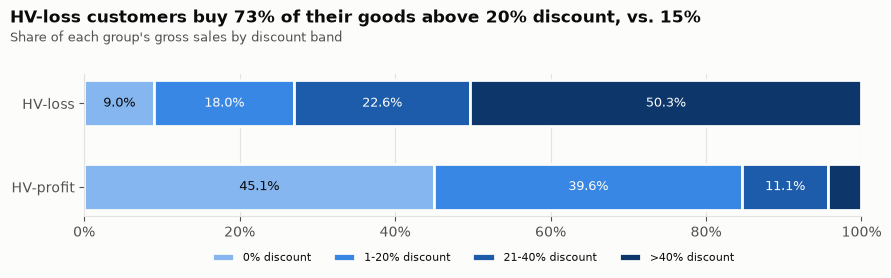

In [9]:
mix = cc.group_mix(con, "discount_band").pivot(index="volume_group", columns="value",
                                               values="gross_share")[["0%", "1-20%", "21-40%", ">40%"]]
fig, ax = plt.subplots(figsize=(9, 3.0))
groups = ["HV-profit", "HV-loss"]
left = np.zeros(len(groups))
for band, color in zip(mix.columns, BAND_COLORS):
    values = mix.loc[groups, band].to_numpy()
    ax.barh(groups, values * 100, left=left * 100, color=color, height=0.55,
            edgecolor=SURFACE, linewidth=2, label=f"{band} discount")
    for y, (l, v) in enumerate(zip(left, values)):
        if v >= 0.06:
            ax.text((l + v / 2) * 100, y, f"{v:.1%}", ha="center", va="center", fontsize=9,
                    color=TEXT if color == BAND_COLORS[0] else SURFACE)
    left += values
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
add_titles(fig, "HV-loss customers buy 73% of their goods above 20% discount, vs. 15%",
           "Share of each group's gross sales by discount band", top=0.80)
save(fig, "02_discount_mix")

In [10]:
show(cc.mix_vs_rate(con), pct=["share_of_gap_from_mix"], decimals=3)

,scenario,profit_per_gross_dollar,share_of_gap_from_mix
0,HV-loss actual,-0.128,nan%
1,HV-profit actual,0.169,nan%
2,"HV-loss rates, HV-profit discount mix",0.103,77.9%
3,"HV-profit rates, HV-loss discount mix",-0.108,93.2%


HV-loss customers lose 12.8¢ per dollar of gross sales; HV-profit customers earn 16.9¢.
Giving HV-loss customers HV-profit's discount mix (keeping their own margins within each
band) lifts them to +10.3¢. **The discount mix explains 78-93% of the profit gap**,
depending on which group's rates are held fixed.

### 3.3 Products

In [11]:
category = cc.mix_comparison(con, "category")
show(category, pct=["HV-loss share", "HV-profit share"], money=["HV-loss profit", "HV-profit profit"])
show(pd.DataFrame([cc.share_ci(con, "category", ["Furniture"])]), decimals=2)

,HV-loss share,HV-profit share,difference (pp),HV-loss profit,HV-profit profit
value,,,,,
Office Supplies,32.8%,29.2%,3.60,"$-20,024","$75,060"
Technology,41.3%,41.6%,-0.31,"$-22,047","$106,999"
Furniture,25.9%,29.2%,-3.30,"$-10,713","$18,287"


,values,HV-loss share,HV-profit share,difference (pp),ci_low (pp),ci_high (pp)
0,Furniture,0.26,0.29,-3.30,-12.96,7.02


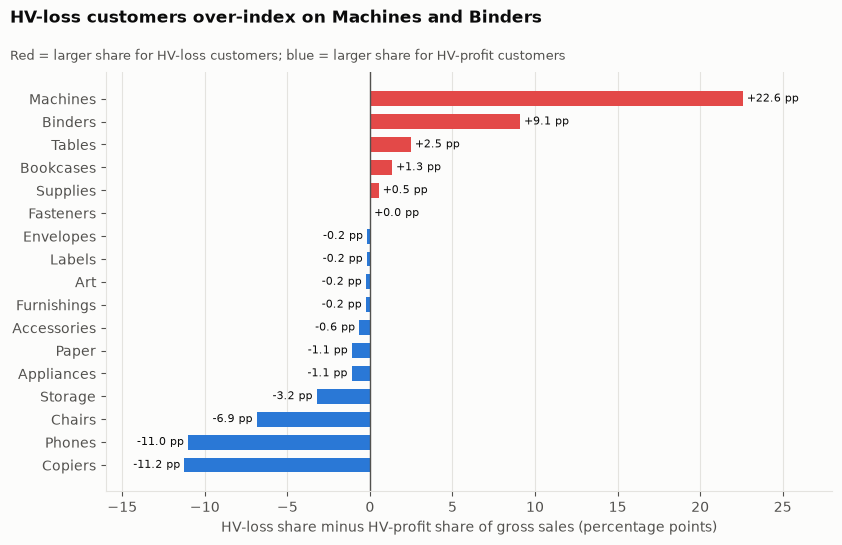

In [12]:
sub = cc.mix_comparison(con, "sub_category").sort_values("difference (pp)")
fig, ax = plt.subplots(figsize=(8.5, 5.6))
colors = [LOSS if v > 0 else BLUE for v in sub["difference (pp)"]]
bars = ax.barh(sub.index, sub["difference (pp)"], color=colors, height=0.65)
for bar, v in zip(bars, sub["difference (pp)"]):
    ax.annotate(f"{v:+.1f} pp", (v, bar.get_y() + bar.get_height() / 2),
                xytext=(3 if v >= 0 else -3, 0), textcoords="offset points", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=TEXT)
ax.axvline(0, color=TEXT_2, lw=1)
ax.set_xlim(-16, 28)
ax.grid(axis="y", visible=False)
ax.set_xlabel("HV-loss share minus HV-profit share of gross sales (percentage points)")
add_titles(fig, "HV-loss customers over-index on Machines and Binders",
           "Red = larger share for HV-loss customers; blue = larger share for HV-profit customers",
           top=0.88)
save(fig, "03_subcategory_gap")

In [13]:
show(cc.subcategory_buyers(con, ["Machines", "Binders", "Tables"]),
     pct=["largest_customer_share"], money=["profit", "gross_sales"])

,sub_category,customers_buying,customers_losing,profit,gross_sales,largest_customer_share
0,Machines,15,15,"$-25,478","$134,755",34.8%
1,Binders,42,30,"$-20,093","$86,924",12.7%
2,Tables,23,20,"$-8,203","$46,303",15.5%


Category mix is the same (Furniture difference −3.3 pp, interval includes 0), but the
sub-category mix is not: Machines are 32.6% of HV-loss gross sales vs. 10.0%, and Binders
21.0% vs. 12.0%. All 15 HV-loss customers who buy Machines lose money on them (one
customer accounts for 35% of that Machines volume); 30 of the 42 who buy Binders lose on
them. HV-loss customers rarely buy the high-margin Copiers and Phones.

### 3.4 Regions and states

In [14]:
show(cc.mix_comparison(con, "region"), pct=["HV-loss share", "HV-profit share"],
     money=["HV-loss profit", "HV-profit profit"])
show(pd.DataFrame([cc.share_ci(con, "state", ["Texas", "Illinois"]),
                   cc.share_ci(con, "region", ["Central"])]), decimals=2)

,HV-loss share,HV-profit share,difference (pp),HV-loss profit,HV-profit profit
value,,,,,
South,29.7%,14.1%,15.65,"$-12,592","$29,276"
Central,28.8%,22.3%,6.51,"$-19,966","$43,045"
East,30.0%,30.4%,-0.45,"$-18,210","$70,080"
West,11.5%,33.2%,-21.70,"$-2,016","$57,946"


,values,HV-loss share,HV-profit share,difference (pp),ci_low (pp),ci_high (pp)
0,Texas + Illinois,0.27,0.11,16.03,4.59,29.43
1,Central,0.29,0.22,6.51,-6.04,20.86


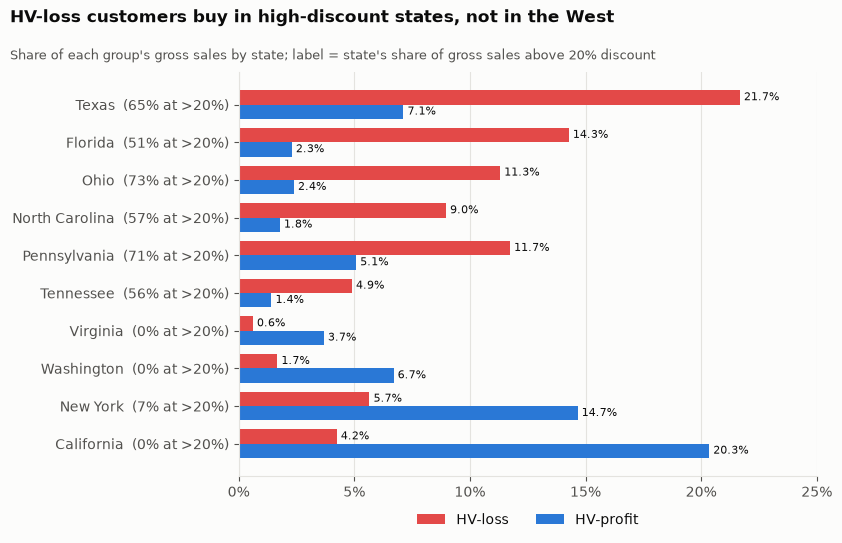

In [15]:
states = cc.mix_comparison(con, "state")
picked = pd.concat([states.head(6), states.tail(4)])
levels = cc.state_discount_levels(con, list(picked.index)).set_index("state")
plot = picked.iloc[::-1]
labels = [f"{s}  ({levels.loc[s, 'gross_share_above_20']:.0%} at >20%)" for s in plot.index]

fig, ax = plt.subplots(figsize=(8.5, 5.6))
y = np.arange(len(plot))
h = 0.38
for offset, group in [(h / 2, "HV-loss"), (-h / 2, "HV-profit")]:
    values = plot[f"{group} share"] * 100
    bars = ax.barh(y + offset, values, height=h, color=GROUP_COLORS[group], label=group)
    for bar, v in zip(bars, values):
        ax.annotate(f"{v:.1f}%", (v, bar.get_y() + bar.get_height() / 2), xytext=(3, 0),
                    textcoords="offset points", va="center", fontsize=8, color=TEXT)
ax.set_yticks(y, labels)
ax.set_xlim(0, 25)
ax.xaxis.set_major_formatter("{x:.0f}%")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.06))
add_titles(fig, "HV-loss customers buy in high-discount states, not in the West",
           "Share of each group's gross sales by state; label = state's share of gross sales above 20% discount",
           top=0.88)
save(fig, "04_state_gap")

In [16]:
show(levels.loc[picked.index], pct=["avg_discount", "gross_share_above_20", "profit_margin"])

,region,order_lines,avg_discount,gross_share_above_20,profit_margin
value,,,,,
Texas,Central,985,37.0%,64.8%,-15.1%
Florida,South,383,29.9%,50.6%,-3.8%
Ohio,East,468,32.5%,73.2%,-21.7%
North Carolina,South,249,28.4%,56.5%,-13.5%
Pennsylvania,East,587,32.9%,71.1%,-13.4%
Tennessee,South,183,29.1%,55.6%,-17.4%
Virginia,South,224,0.0%,0.0%,26.3%
Washington,West,506,6.4%,0.0%,24.1%
New York,East,"1,128",5.5%,6.7%,23.8%


The regional difference is a **state** difference. West is 11.5% of HV-loss gross sales vs.
33.2%; Central is not significantly different (interval includes 0). The states where
HV-loss customers over-index (Texas, Florida, Ohio, North Carolina, Pennsylvania,
Tennessee) all sell more than half of their gross sales above 20% discount, while
California, Washington and Virginia sell none. This extends step 2's Texas/Illinois
finding to Eastern and Southern states.

### 3.5 One bad line or a pattern?

In [17]:
show(cc.loss_concentration(customers), pct=["median worst-line share of losses"],
     money=["median worst line profit ($)"])
show(cc.worst_line_summary(con), pct=["median_discount"], money=["median_profit"])

,HV-loss customers,median worst-line share of losses,worst line > 50% of losses,profitable without their worst line,median worst line profit ($)
0,43,82.4%,35,25,$-950


,sub_category,discount_band,customers,median_profit,median_discount
0,Binders,>40%,13,"$-1,144",80.0%
1,Machines,>40%,11,$-950,70.0%
2,Tables,21-40%,5,$-620,40.0%
3,Supplies,1-20%,2,$-918,20.0%
4,Appliances,>40%,2,$-820,80.0%
5,Machines,21-40%,2,$-812,40.0%
6,Bookcases,>40%,2,"$-1,014",60.0%
7,Tables,>40%,2,$-531,47.5%
8,Phones,21-40%,2,$-298,40.0%
9,Bookcases,21-40%,1,$-317,32.0%


For the median HV-loss customer, the single worst line makes up 82% of their line-level
losses; **25 of the 43 would be profitable without it**. 41 of the 43 worst lines are
discounted above 20%, most often Binders at a median 80% off and Machines at 70% off.

## 4. Can the segmentations find them?

Lift = a segment's share of the 43 HV-loss customers divided by its share of all
customers. "Loss rate among HV" = HV-loss / all high-volume customers in the segment
(base rate 43 / 199 = 21.6%).

In [18]:
for column in ["rfm_segment", "cluster", "cluster_contrast"]:
    print(column)
    table = cc.segment_crosstab(customers, column)
    show(table, pct=["share of HV-loss", "share of all", "loss rate among HV"])
show(cc.segmentation_agreement(customers), decimals=3)

rfm_segment


volume_group,HV-loss,HV-profit,Other,all customers,share of HV-loss,share of all,lift,loss rate among HV
rfm_segment,,,,,,,,
Loyal,10,21,52,83,23.3%,10.5%,2.22,32.3%
Champions,13,68,103,184,30.2%,23.2%,1.30,16.0%
"Frequent, quiet lately",5,34,51,90,11.6%,11.3%,1.02,12.8%
Needs attention,4,5,67,76,9.3%,9.6%,0.97,44.4%
"Infrequent, quiet lately",7,12,209,228,16.3%,28.8%,0.57,36.8%
Promising,4,16,112,132,9.3%,16.6%,0.56,20.0%


cluster


volume_group,HV-loss,HV-profit,Other,all customers,share of HV-loss,share of all,lift,loss rate among HV
cluster,,,,,,,,
"Active, heavy-discount",39,16,101,156,90.7%,19.7%,4.61,70.9%
"Active, regular",3,136,261,400,7.0%,50.4%,0.14,2.2%
"Quiet, low volume",1,4,232,237,2.3%,29.9%,0.08,20.0%


cluster_contrast


volume_group,HV-loss,HV-profit,Other,all customers,share of HV-loss,share of all,lift,loss rate among HV
cluster_contrast,,,,,,,,
Active,41,151,304,496,95.3%,62.5%,1.52,21.4%
Quiet,2,5,290,297,4.7%,37.5%,0.12,28.6%


,a,b,ari
0,rfm_segment,cluster,0.163
1,rfm_segment,cluster_contrast,0.213
2,cluster,cluster_contrast,0.563


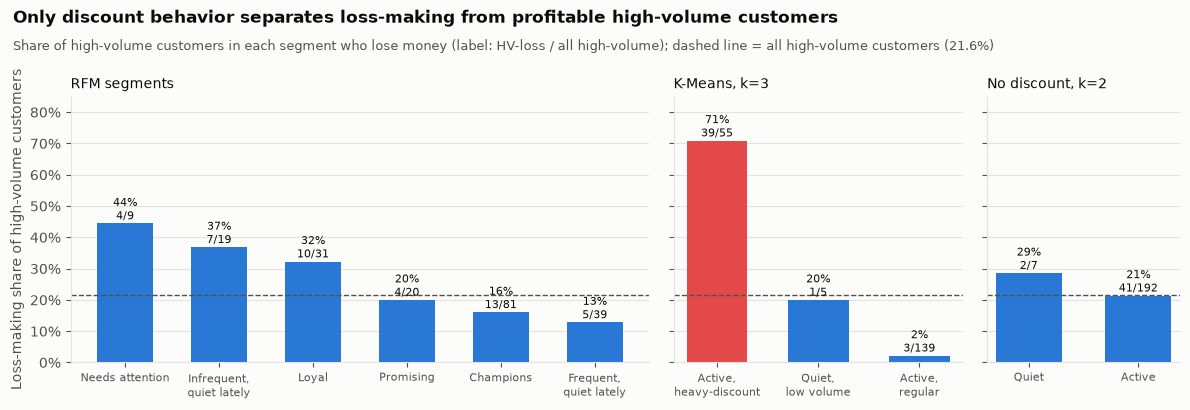

In [19]:
base_rate = (customers.volume_group == "HV-loss").sum() / customers.is_high_volume.sum()
panels = [("rfm_segment", "RFM segments"), ("cluster", "K-Means, k=3"),
          ("cluster_contrast", "No discount, k=2")]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), gridspec_kw={"width_ratios": [6, 3, 2]}, sharey=True)
for ax, (column, heading) in zip(axes, panels):
    t = cc.segment_crosstab(customers, column).sort_values("loss rate among HV", ascending=False)
    names = [n.replace(", ", ",\n") for n in t.index]
    colors = [LOSS if n == "Active, heavy-discount" else BLUE for n in t.index]
    bars = ax.bar(names, t["loss rate among HV"] * 100, color=colors, width=0.6)
    for bar, loss, hv, rate in zip(bars, t["HV-loss"], t["HV-loss"] + t["HV-profit"], t["loss rate among HV"]):
        ax.annotate(f"{rate:.0%}\n{int(loss)}/{int(hv)}",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=8, color=TEXT)
    ax.axhline(base_rate * 100, color=TEXT_2, lw=1, ls="--")
    ax.set_title(heading, loc="left", fontsize=10, color=TEXT)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Loss-making share of high-volume customers")
axes[0].yaxis.set_major_formatter("{x:.0f}%")
axes[0].set_ylim(0, 85)
add_titles(fig, "Only discount behavior separates loss-making from profitable high-volume customers",
           "Share of high-volume customers in each segment who lose money (label: HV-loss / all high-volume); "
           f"dashed line = all high-volume customers ({base_rate:.1%})",
           top=0.84)
save(fig, "05_segment_loss_rate")

- **RFM cannot spot them:** 23 of the 43 score as Champions or Loyal, and no RFM segment
  isolates them (agreement with the clusters: ARI 0.16).
- **K-Means with the discount feature finds them:** the "Active, heavy-discount" cluster
  holds 39 of the 43 (91%) while holding 20% of customers (lift 4.6); 71% of the
  high-volume customers in it lose money, vs. 2% in "Active, regular".
- **The contrast settles it:** without the discount feature, the "Active" cluster's loss
  rate among high-volume customers (21%) equals the base rate. Recency, frequency and
  volume alone do not separate the groups; discount behavior does.

## 5. Sensitivity

The comparison repeated under the alternative high-volume definitions agreed in the plan.

In [20]:
sens = cc.sensitivity(con, customers).set_index("definition").T
display(sens)

definition,gross sales top 25% (primary),gross sales top 20%,net sales top 25%,quantity top 25%,"primary, excluding |profit| < $100"
HV-loss n,43.000000,34.000000,26.000000,35.000000,40.000000
HV-loss >20% disc share,0.729899,0.739901,0.721237,0.603627,0.740486
HV-loss TX+IL share,0.269719,0.249848,0.218643,0.375180,0.277595
HV-loss median recency,72.000000,52.000000,62.500000,48.000000,69.000000
HV-loss median orders,7.000000,7.000000,7.000000,8.000000,7.000000
HV-profit n,156.000000,125.000000,173.000000,168.000000,150.000000
HV-profit >20% disc share,0.153679,0.152876,0.139715,0.170372,0.143731
HV-profit TX+IL share,0.109439,0.105678,0.102945,0.123198,0.109141
HV-profit median recency,49.000000,51.000000,52.000000,44.000000,49.000000
HV-profit median orders,8.000000,8.000000,8.000000,9.000000,8.000000


The core result holds under every definition: HV-loss customers buy 60-74% of their gross
sales above 20% discount (vs. 14-17%), ship more to Texas and Illinois (22-38% vs.
10-12%), and 80-91% of them fall in the heavy-discount cluster. The recency difference is
**not** robust (HV-loss median 48-72 days depending on the definition).

## Business insight

**The loss-making high-volume customers are not smaller, newer or lapsing customers.**
Their recency, tenure, frequency and volume are close to those of profitable high-volume
customers. What sets them apart:

- **73% of what they buy is discounted above 20%,** against 15%, and that discount mix
  explains most (78-93%) of the profit gap.
- **They're concentrated in high-discount states,** including Ohio, Pennsylvania, Texas,
  Florida and North Carolina, not in the West.
- **They're concentrated in Machines and Binders.**
- **For most of them, a single deeply discounted order turns the customer from profitable
  to loss-making:** 25 of the 43 would be profitable without their worst line.

RFM would rank half of them as top customers. A segmentation that includes discount
behavior finds 91% of them.

**Recommendation (an inference from these results, not a tested finding):** the problem
is how large orders are priced in specific states, not which customers the company
serves. A discount cap or approval step for deep discounts on Machines and Binders in
the high-discount states would target exactly the lines that turn good customers into
loss-makers. This analysis did not test the effect of such a policy (for example, whether
customers would still buy without the discount); step 4 and an A/B test or pilot would
be needed to estimate it.

**Caveats:**
1. Association, not cause: profit is computed after the discount, so part of the link is
   arithmetic.
2. Discount and state cannot be separated here, because discounts are set by state.
   Step 4's model can test them separately.
3. Small groups: 43 HV-loss customers, 15 of them Machines buyers, and one large Machines
   customer.
4. The heavy-discount cluster was partly expected, since it is built on discount share.
   The contrast run is what makes the result meaningful.

**Next (step 4):** predict loss-making order lines from features known at order time,
and test whether discount, state and sub-category each matter once the others are held
fixed.

In [21]:
con.close()